Based on https://www.kaggle.com/datasets/vishala28/swat-dataset-secure-water-treatment-system?select=normal.csv

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import ruptures as rpt
import numpy as np


In [57]:
# Specify the path to the dataset
DATA_PATH = "normal.csv"

In [58]:
# Load the dataset
df = pd.read_csv(DATA_PATH)

df

,Timestamp,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,...,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,Normal/Attack
0,28/12/2015 10:00:00 AM,2.427057,522.8467,2.0,2,1,262.0161,8.396437,328.6337,2.445391,...,2,1,250.8652,1.649953,189.5988,0.000128,1,1,1,Normal
1,28/12/2015 10:00:01 AM,2.446274,522.8860,2.0,2,1,262.0161,8.396437,328.6337,2.445391,...,2,1,250.8652,1.649953,189.6789,0.000128,1,1,1,Normal
2,28/12/2015 10:00:02 AM,2.489191,522.8467,2.0,2,1,262.0161,8.394514,328.6337,2.442316,...,2,1,250.8812,1.649953,189.6789,0.000128,1,1,1,Normal
3,28/12/2015 10:00:03 AM,2.534350,522.9645,2.0,2,1,262.0161,8.394514,328.6337,2.442316,...,2,1,250.8812,1.649953,189.6148,0.000128,1,1,1,Normal
4,28/12/2015 10:00:04 AM,2.569260,523.4748,2.0,2,1,262.0161,8.394514,328.6337,2.443085,...,2,1,250.8812,1.649953,189.5027,0.000128,1,1,1,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1387093,28/12/2015 9:59:55 AM,2.460366,523.0430,NaN,2,1,NaN,8.396437,328.5055,2.442316,...,2,1,250.8171,1.778105,189.8552,0.000128,1,1,1,Normal
1387094,28/12/2015 9:59:56 AM,2.448836,522.9645,NaN,2,1,NaN,8.396437,328.5055,2.442316,...,2,1,250.8171,1.778105,189.5027,0.000128,1,1,1,Normal
1387095,28/12/2015 9:59:57 AM,2.434744,522.8860,NaN,2,1,NaN,8.396437,328.6337,2.444879,...,2,1,250.8171,1.778105,189.5027,0.000128,1,1,1,Normal
1387096,28/12/2015 9:59:58 AM,2.428338,522.9252,NaN,2,1,NaN,8.396437,328.6337,2.445391,...,2,1,250.8171,1.649953,189.5027,0.000128,1,1,1,Normal


In [59]:
# Isolate pump 1 at stage 1

pump1_data = df['P101']
pump1_data.isnull().sum()

0

In [ ]:
# downsample pump1_data to every 30th value to reduce noise and make change point detection more effective
pump1_data = pump1_data[::30].reset_index(drop=True)
pump1_data

0        2
1        2
2        2
3        2
4        2
        ..
46232    2
46233    2
46234    2
46235    2
46236    2
Name: P101, Length: 46237, dtype: int64

In [61]:
pump1_data.values

array([2, 2, 2, ..., 2, 2, 2], dtype=int64)

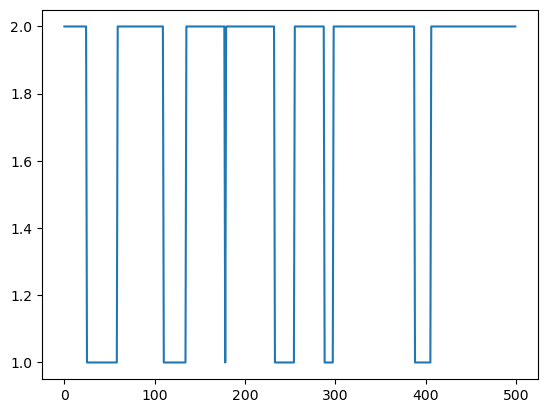

In [62]:
# plot first 500 values of pump1_data
sample_size = 500

plt.plot(pump1_data.head(sample_size))
plt.show()

In [63]:

    
# 2. Configure PELT
# 'l2' (Least Squares) is best for shifts in the mean
algo = rpt.Pelt(model="l2", jump=1).fit(pump1_data.head(sample_size).values)

# 3. Predict change points
# The 'pen' value is the sensitivity. 
result = algo.predict(pen=1.5)

result

[25, 59, 110, 135, 233, 255, 288, 298, 388, 406, 500]

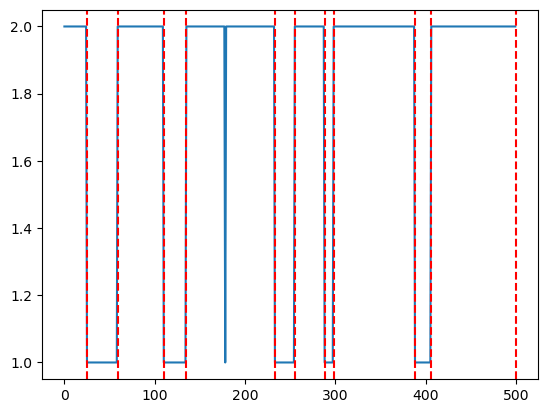

In [64]:
# plot results of change point detection onto the original signal

plt.plot(pump1_data.head(sample_size))
for res in result:
    plt.axvline(x=res, color='r', linestyle='--', label='Change Point')
plt.show()

In [65]:
# 4. Calculate Dwell Times
change_points = [0] + result
dwell_times = np.diff(change_points)

print("Dwell Times:", dwell_times)

avg_dwell = float(np.mean(dwell_times))
avg_dwell

Dwell Times: [25 34 51 25 98 22 33 10 90 18 94]


45.45454545454545

# Testing on Generator Output

In [68]:
traj = np.load('../../artifacts/generation/005b576e3c189ad7/trajectory.npz')
traj

NpzFile '../../artifacts/generation/005b576e3c189ad7/trajectory.npz' with keys: noise, x

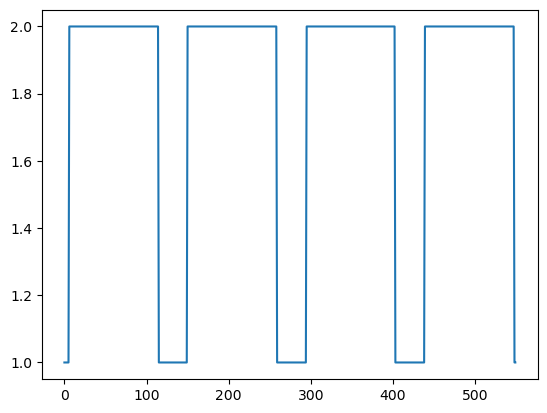

In [70]:
data = traj["x"]

plt.plot(data)

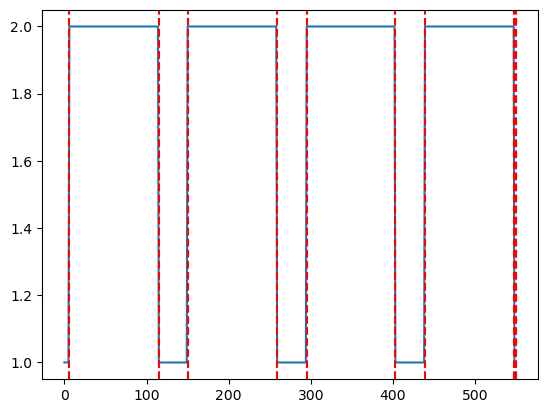

In [71]:
# 2. Configure PELT
# 'l2' (Least Squares) is best for shifts in the mean
algo = rpt.Pelt(model="l2", jump=1).fit(data)

# 3. Predict change points
# The 'pen' value is the sensitivity. 
result = algo.predict(pen=1.5)

plt.plot(data)
for res in result:
    plt.axvline(x=res, color='r', linestyle='--', label='Change Point')
plt.show()

In [ ]:
import sys
import os

# Get the absolute path of the current script's directory or root folder
# and add the 'src' subdirectory to python's module search path
src_path = os.path.abspath("src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Now you can import your module
from src.analysis.param_estimates import estimated_dwell_time

dwell = estimated_dwell_time(data)

NameError: name '__file__' is not defined